# Final Project - DSC 100 
## **Predicting EV Charging Station Occupancy Using Caltech ACN-Data**
<br/>
<hr style="border: 5px solid #003262;" />
<hr style="border: 1px solid #fdb515;" />

### **Introduction**

In this project, my main goal is to predict how long an electric vehicle (EV) will occupy a charging station based on its arrival time and other available information. I chose this topic because EVs are sometimes left connected to charging stations for long periods, even after they have finished charging. This can cause inconvenience for other drivers who need to use the station.

Through this project, I want to investigate patterns in charging station occupancy and determine whether machine learning can predict the duration of charging sessions.

<br>

---

### **Dataset**

For this project, I will use the **Adaptive Charging Network (ACN-Data)** dataset provided by the California Institute of Technology (Caltech).

I selected two separate datasets from different academic terms to train and evaluate my machine learning models.

**1. Training Dataset — Spring 2019**

- **File:** `acndata_sessions_2018_2019_spring_sem.json`
- **Time Range:** April 1, 2019 – June 14, 2019
- **Purpose:** Used for exploratory data analysis, model training, and cross-validation.

**2. Testing Dataset — Winter 2020**

- **File:** `acndata_sessions_2019_2020_winter_sem.json`
- **Time Range:** January 6, 2020 – March 18, 2020
- **Purpose:** Used as an independent testing dataset to evaluate how well the trained models perform on unseen charging sessions.

I chose these periods because they primarily occurred before major COVID-19 campus restrictions, which significantly changed how students and employees used campus facilities. By separating the two academic terms, I want to evaluate whether patterns learned from historical charging sessions can generalize to a different period.

However, seasonal differences between the spring and winter terms, as well as possible changes in behavior during early March 2020, may affect the results.

**Dataset Source:** [Caltech Adaptive Charging Network (ACN-Data)](https://ev.caltech.edu/dataset)

In [1]:
# Run this cell to set up your notebook; no further action is needed.
import json # dataset is in Json form
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
sns.set()
sns.set_context("talk")

from IPython.display import display, Latex, Markdown

<br>

---

### **Data Cleaning**

Before I explore the data, I need to check if the Spring 2019 dataset is clean enough to use. In this section, I load the data, check for missing values and duplicates, convert the timestamps, and look at sessions with strange durations.

For each problem, I show how many sessions are affected and explain what I decided to do. I only clean the Spring 2019 dataset here. The Winter 2020 dataset will go through the same steps later, so it stays as unseen data until the final test.

#### **1. Loading the Data**

The file is in JSON format. The charging sessions are stored under the `_items` key, so I load the file with `json` first and then turn `_items` into a DataFrame. Each row is one charging session.

In [2]:
with open('data/raw/acndata_sessions_2018_2019_spring_sem.json', 'r') as f:
    data = json.load(f)

df = pd.DataFrame(data['_items'])

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

df.head()

Rows: 2447
Columns: 13


,_id,clusterID,connectionTime,disconnectTime,doneChargingTime,kWhDelivered,sessionID,siteID,spaceID,stationID,timezone,userID,userInputs
0,5cb673cbf9af8b4ced04ad98,0039,"Mon, 01 Apr 2019 02:11:40 GMT","Mon, 01 Apr 2019 06:32:48 GMT","Mon, 01 Apr 2019 03:17:55 GMT",2.236,2_39_79_377_2019-04-01 02:11:39.943148,0002,CA-325,2-39-79-377,America/Los_Angeles,000001082,"[{'WhPerMile': 400, 'kWhRequested': 16.0, 'mil..."
1,5cb673cbf9af8b4ced04ad99,0039,"Mon, 01 Apr 2019 02:34:05 GMT","Mon, 01 Apr 2019 04:39:32 GMT","Mon, 01 Apr 2019 04:37:41 GMT",7.027,2_39_139_28_2019-04-01 02:34:04.961671,0002,CA-303,2-39-139-28,America/Los_Angeles,000000781,"[{'WhPerMile': 357, 'kWhRequested': 7.14, 'mil..."
2,5cb673cbf9af8b4ced04ad9a,0039,"Mon, 01 Apr 2019 04:12:23 GMT","Mon, 01 Apr 2019 15:33:16 GMT","Mon, 01 Apr 2019 10:52:49 GMT",43.699,2_39_131_30_2019-04-01 04:12:22.668145,0002,CA-305,2-39-131-30,America/Los_Angeles,000000489,"[{'WhPerMile': 500, 'kWhRequested': 100.0, 'mi..."
3,5cb7c521f9af8b50839305be,0039,"Mon, 01 Apr 2019 13:45:15 GMT","Mon, 01 Apr 2019 21:51:25 GMT","Mon, 01 Apr 2019 17:25:40 GMT",19.190,2_39_88_24_2019-04-01 13:45:15.046490,0002,CA-314,2-39-88-24,America/Los_Angeles,000000560,"[{'WhPerMile': 273, 'kWhRequested': 21.84, 'mi..."
4,5cb7c521f9af8b50839305bf,0039,"Mon, 01 Apr 2019 14:19:51 GMT","Mon, 01 Apr 2019 15:48:01 GMT","Mon, 01 Apr 2019 15:47:56 GMT",9.832,2_39_78_366_2019-04-01 14:19:51.094877,0002,CA-323,2-39-78-366,America/Los_Angeles,000000569,"[{'WhPerMile': 300, 'kWhRequested': 27.0, 'mil..."


#### **2. Missing Values**

First, I count the missing values in every column.

In [3]:
missing = pd.DataFrame({
    "missing": df.isna().sum(),
    "percent": (df.isna().mean() * 100).round(1)
})

missing

,missing,percent
_id,0,0.0
clusterID,0,0.0
connectionTime,0,0.0
disconnectTime,0,0.0
doneChargingTime,14,0.6
kWhDelivered,0,0.0
sessionID,0,0.0
siteID,0,0.0
spaceID,0,0.0
stationID,0,0.0


Only three columns have missing values.

- `doneChargingTime` is missing in 14 sessions (0.6%). I look at these sessions in step 8, after converting the timestamps.
- `userID` and `userInputs` are missing in the same 336 sessions (13.7%). In ACN-Data, the user information only exists when the driver registers the session through the mobile app, so these are sessions from drivers who did not do that.

I decided not to remove the sessions without user information. They are still real charging sessions with real connection and disconnection times, and I do not plan to use `userID` or `userInputs` as model features.

#### **3. Duplicates**

Next, I check if any session was saved more than once. I check the two ID columns.

In [4]:
print("Duplicated _id:", df["_id"].duplicated().sum())
print("Duplicated sessionID:", df["sessionID"].duplicated().sum())

Duplicated _id: 0
Duplicated sessionID: 0


There are no duplicated sessions

#### **4. Columns I Do Not Need**

Some columns are IDs, and some may have the same value in every row. I count the unique values in each of them.

In [5]:
id_cols = ["_id", "sessionID", "siteID", "clusterID", "timezone", "spaceID", "stationID", "userID"]

print(df["timezone"].unique())
df[id_cols].nunique()

<StringArray>
['America/Los_Angeles']
Length: 1, dtype: str


_id          2447
sessionID    2447
siteID          1
clusterID       1
timezone        1
spaceID        52
stationID      52
userID        172
dtype: int64

In [6]:
# check if each parking space (spaceID) corresponds to exactly one charging station (stationID)
print(df.groupby("spaceID")["stationID"].nunique().max())
print(df.groupby("stationID")["spaceID"].nunique().max())

1
1


- `siteID`, `clusterID` and `timezone` have only one value, so they can not explain any difference between sessions. I drop them.
- `_id` and `sessionID` are both unique for every row. I keep `sessionID` to identify a session and drop `_id`.
- `spaceID` and `stationID` both have 52 values, and every space has exactly one station. They give the same information, so I keep only `stationID`.
- `userID` has 172 different users. I keep it for the analysis.

In [7]:
df = df.drop(columns=["_id", "siteID", "clusterID", "timezone", "spaceID"])

df.columns.tolist()

['connectionTime',
 'disconnectTime',
 'doneChargingTime',
 'kWhDelivered',
 'sessionID',
 'stationID',
 'userID',
 'userInputs']

#### **5. Converting the Timestamps**

The three time columns are saved as text in GMT, for example `Mon, 01 Apr 2019 02:11:40 GMT`. Caltech is in California, so I convert them to California local time.

This is important for my project because the arrival hour and the day of the week are different in GMT. For example, 2 AM on Monday in GMT is 7 PM on Sunday in California.

In [8]:
cols = ["connectionTime", "disconnectTime", "doneChargingTime"]


df[cols] = df[cols].apply(
    lambda col: pd.to_datetime(
        col, utc=True
    ).dt.tz_convert("America/Los_Angeles")
)


# keep the sessions in time order
df = df.sort_values("connectionTime").reset_index(drop=True)

In [9]:
print("First arrival:", df["connectionTime"].min())
print("Last arrival: ", df["connectionTime"].max())


First arrival: 2019-03-31 19:11:40-07:00
Last arrival:  2019-06-14 16:55:51-07:00


After the conversion, the date range of the download that was in GMT is converted PST. However, I noticed that the data exceeds the limit set when I requested the Json data(I requested 1st of April as start but the min date is March) I decided to keep them, because they are real sessions and they are only a few hours before April 1.

#### **6. Duration and Time Columns**

Now I can calculate how long each car stayed at the station.

- `occupancy_hours`: from plugging in to unplugging. This is the value I want to predict.
- `charging_interval_hours`: from plugging in to the last time the car was charging.
- `idle_hours`: from the last time the car was charging to unplugging. During this time the car is only blocking the station.

In [10]:
df["occupancy_hours"] = (
    df["disconnectTime"] - df["connectionTime"]
).dt.total_seconds() / 3600

df["charging_interval_hours"] = (
    df["doneChargingTime"] - df["connectionTime"]
).dt.total_seconds() / 3600

df["idle_hours"] = (
    df["disconnectTime"] - df["doneChargingTime"]
).dt.total_seconds() / 3600

In [11]:
df["day_of_week"] = df["connectionTime"].dt.day_of_week # Monday = 0, Sunday = 6
df["arrival_hour"] = df["connectionTime"].dt.hour
df["departure_hour"] = df["disconnectTime"].dt.hour
df["month"] = df["connectionTime"].dt.month
df["is_weekend"] = (df["day_of_week"] >= 5).astype(int)

In [12]:
duration_cols = ["occupancy_hours", "charging_interval_hours", "idle_hours"]

df[duration_cols].describe().round(2)

,occupancy_hours,charging_interval_hours,idle_hours
count,2447.00,2433.00,2433.00
mean,6.39,2.84,3.57
std,6.18,3.82,4.75
min,0.09,-0.02,-0.02
25%,2.56,1.18,0.20
50%,6.24,1.90,2.36
75%,8.74,3.62,5.96
max,118.91,113.01,112.65


After checking into all the hours, we can see that...

- The minimum of `charging_interval_hours` and `idle_hours` is negative, but a duration can not be negative.
- `charging_interval_hours` and `idle_hours` have 2,433 values instead of 2,447.
- The maximum of `occupancy_hours` is almost 119 hours, while 75% of the sessions are shorter than 9 hours.

I will check this.... ( WHY DO THIS TO ME D: )

#### **7. Finding Issues ( Negative Durations )**

In [13]:
neg_charging = df["charging_interval_hours"] < 0
neg_idle = df["idle_hours"] < 0

print("Negative charging interval:", neg_charging.sum())
print("Negative idle time:", neg_idle.sum())

# Negative Idles in seconds
(df.loc[neg_idle, "idle_hours"] * 3600).describe().round(1)

Negative charging interval: 2
Negative idle time: 79


count    79.0
mean    -55.5
std      12.0
min     -60.0
25%     -59.0
50%     -59.0
75%     -58.0
max      -1.0
Name: idle_hours, dtype: float64

79 sessions have a negative idle time, which means `doneChargingTime` is later than `disconnectTime`. A car can not charge after it is unplugged. However, the difference is never more than 60 seconds, and for most of these sessions it is almost exactly one minute. The 2 sessions with a negative charging interval are the same kind of problem, where `doneChargingTime` is about one minute before `connectionTime`.

Because the error is so small and so regular, I think it comes from how the times were recorded and not from the drivers. I decided not to delete these sessions. Instead, I set the negative values to 0. 

In [14]:
cols = ["charging_interval_hours", "idle_hours"]

df[cols] = df[cols].clip(lower=0)

print("Negative charging interval:", (df["charging_interval_hours"] < 0).sum())
print("Negative idle time:", (df["idle_hours"] < 0).sum())

Negative charging interval: 0
Negative idle time: 0


Now all values under 0 are now 0

#### **8. Missing doneChargingTime**

Previously, I found 14 sessions without `doneChargingTime`.

In [15]:
no_done = df["doneChargingTime"].isna()
print("Sessions without doneChargingTime:", no_done.sum())

df.loc[no_done, "connectionTime"].dt.date.value_counts().sort_index()

Sessions without doneChargingTime: 14


connectionTime
2019-04-07    11
2019-04-08     3
Name: count, dtype: int64

All 14 sessions are from April 7 and April 8. The missing values are not spread randomly over the term, so it looks like the end of charging was not recorded for two days.

These sessions still have a connection and disconnection time, so `occupancy_hours` is correct for them. I decided to keep them. I leave `charging_interval_hours` and `idle_hours` empty for these 14 sessions, because filling them with a guess would add information that was never measured.

#### **9. Sessions with Weird Lengths**

FINALLY LAST THING TO CHECK

In [16]:
print("Shortest session (minutes):", round(df["occupancy_hours"].min() * 60, 1))
print("Sessions under 15 minutes:", (df["occupancy_hours"] < 0.25).sum())
print("Smallest kWhDelivered:", df["kWhDelivered"].min())
print()
print("Longest session (hours):", round(df["occupancy_hours"].max(), 1))
print("Sessions over 24 hours:", (df["occupancy_hours"] > 24).sum())
print("Sessions over 48 hours:", (df["occupancy_hours"] > 48).sum())

Shortest session (minutes): 5.1
Sessions under 15 minutes: 13
Smallest kWhDelivered: 0.518

Longest session (hours): 118.9
Sessions over 24 hours: 22
Sessions over 48 hours: 7


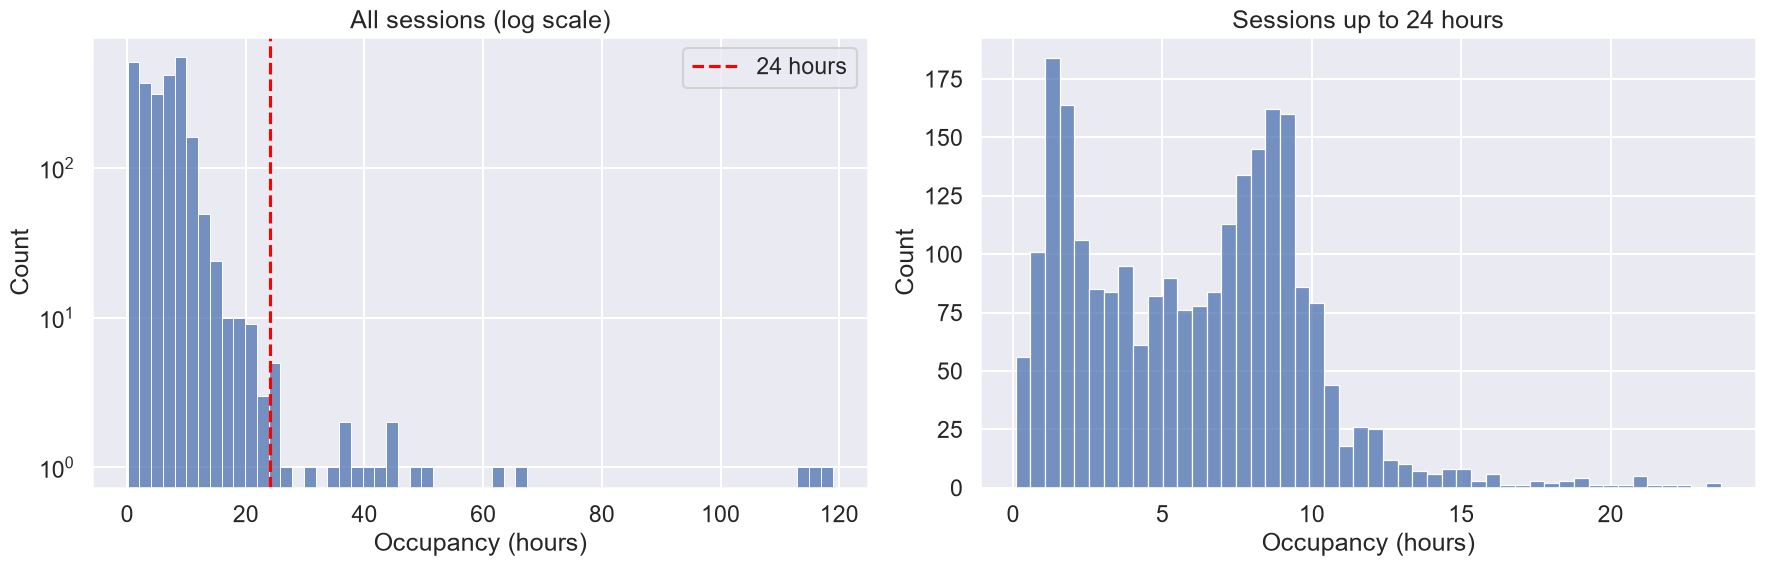

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

sns.histplot(df["occupancy_hours"], bins=60, ax=axes[0])
axes[0].axvline(24, color="red", linestyle="--", label="24 hours")
axes[0].set_yscale("log")
axes[0].set_title("All sessions (log scale)")
axes[0].set_xlabel("Occupancy (hours)")
axes[0].legend()

sns.histplot(df.loc[df["occupancy_hours"] <= 24, "occupancy_hours"], bins=48, ax=axes[1])
axes[1].set_title("Sessions up to 24 hours")
axes[1].set_xlabel("Occupancy (hours)")

plt.tight_layout()
plt.show()

From this graph, you can see most sessions that are usefule for this data is in the rance between 0~24 hours so within a day

In [18]:
# the 10 longest sessions
long_cols = ["connectionTime", "disconnectTime", "occupancy_hours", "idle_hours", "kWhDelivered", "userID", "stationID"]

df.loc[df["occupancy_hours"] > 24, long_cols].sort_values("occupancy_hours", ascending=False).head(10)

,connectionTime,disconnectTime,occupancy_hours,idle_hours,kWhDelivered,userID,stationID
1766,2019-05-23 09:18:45-07:00,2019-05-28 08:13:05-07:00,118.905556,42.330000,1.084,NaN,2-39-138-29
404,2019-04-11 23:06:51-07:00,2019-04-16 19:20:31-07:00,116.227778,3.218056,1.056,NaN,2-39-127-19
1480,2019-05-14 23:05:07-07:00,2019-05-19 17:19:09-07:00,114.233889,112.648056,9.831,000001826,2-39-89-25
831,2019-04-24 18:21:39-07:00,2019-04-27 12:10:47-07:00,65.818889,63.229167,13.960,000001826,2-39-130-31
1156,2019-05-05 02:22:38-07:00,2019-05-07 17:11:38-07:00,62.816667,56.387222,14.062,000001826,2-39-79-377
2205,2019-06-07 15:50:13-07:00,2019-06-09 18:15:36-07:00,50.423056,14.475833,14.882,000001152,2-39-127-19
2235,2019-06-10 08:37:57-07:00,2019-06-12 10:07:39-07:00,49.495000,16.780000,0.896,NaN,2-39-79-382
1446,2019-05-13 21:44:11-07:00,2019-05-15 18:45:11-07:00,45.016667,3.818056,11.833,000001202,2-39-139-28
1142,2019-05-03 23:02:03-07:00,2019-05-05 18:52:55-07:00,43.847778,38.356389,36.880,000000292,2-39-89-25
1832,2019-05-25 16:50:43-07:00,2019-05-27 11:11:02-07:00,42.338611,34.830556,50.229,000000489,2-39-131-30


In [19]:
# do the long sessions come from the same users?
df.loc[df["occupancy_hours"] > 24, "userID"].value_counts(dropna=False).head()

userID
000001202    6
NaN          5
000001826    5
000000489    2
000000292    1
Name: count, dtype: int64

There are 22 sessions longer than 24 hours, and the longest one is almost 119 hours, which is about five days. I do not think these are errors. The timestamps are in the right order, every car received energy, 11 of the 22 sessions come from only two users, and most of them have a very zlong idle time. This looks like cars that were really left at the station(Free parking? kinda smart)

Cars staying too long is exactly the problem I want to study, so I decided not to delete these sessions. However, a few sessions over 100 hours can have a big effect on a linear regression model. For this reason, I mark them with a new column `long_session`, so I can compare the results with and without them later.

The short sessions are not a problem either. The shortest one is about 5 minutes, and every session delivered at least 0.5 kWh, so they are real charging sessions.

In [20]:
df["long_session"] = (df["occupancy_hours"] > 24).astype(int)

df["long_session"].value_counts()

long_session
0    2425
1      22
Name: count, dtype: int64

#### **10. Cleaning Summary**

After cleaning, the dataset still has all 2,447 sessions. I did not delete any session. The only values I changed are the 81 negative durations, which are now 0.

The columns have different roles in the rest of the project.